# Where the 30-minute model is wrong

A model that misses is more instructive than one that hits. Using the logistic model at
`t = 30` (the simplest one that matched XGBoost), this notebook looks at the stories the model
got most wrong on the held-out days and asks what they have in common.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from hn import dataset, db, models

pd.set_option("display.max_colwidth", 80)
FIG = Path("figures"); FIG.mkdir(exist_ok=True)

df = dataset.build(30, trajectory=True)
train, test = dataset.temporal_split(df)
cols = dataset.feature_columns(df)
pipe = models.make_pipeline(models.logistic(), cols).fit(train[cols], train.top30)
test = test.assign(p=pipe.predict_proba(test[cols])[:, 1], score_30m=lambda d: np.expm1(d.log_score).round().astype(int))
test["rank_in_day"] = test.groupby("day").p.rank(ascending=False)

## Late bloomers: top-30 stories the model ranked outside its daily top 30

In [2]:
show = ["title", "domain", "hour_utc", "score_30m", "final_score", "min_to_first_comment", "p", "rank_in_day"]
missed = test[(test.top30 == 1) & (test.rank_in_day > 30)].sort_values("final_score", ascending=False)
print(f"{len(missed)} of {test.top30.sum()} positives missed")
missed[show].head(20)

36 of 58 positives missed


,title,domain,hour_utc,score_30m,final_score,min_to_first_comment,p,rank_in_day
story_id,,,,,,,,
46962996,The Singularity will occur on a Tuesday,campedersen.com,17,2,1262,30.000000,0.456157,122.0
46958399,Europe's $24T Breakup with Visa and Mastercard Has Begun,europeanbusinessmagazine.com,11,4,951,30.000000,0.759387,32.0
46971516,Windows Notepad App Remote Code Execution Vulnerability,cve.org,6,1,767,30.000000,0.202027,467.0
46960675,I started programming when I was 7. I'm 50 now and the thing I loved has cha...,jamesdrandall.com,15,3,762,17.700000,0.724159,39.0
46978966,Amazon Ring's lost dog ad sparks backlash amid fears of mass surveillance,theverge.com,18,6,637,8.433333,0.647195,51.0
46954920,"Frontier AI agents violate ethical constraints 30–50% of time, pressured by ...",arxiv.org,3,2,522,8.083333,0.124041,769.0
46976911,Fluorite – A console-grade game engine fully integrated with Flutter,fluorite.game,16,3,516,30.000000,0.514429,99.0
46967772,The Day the Telnet Died,labs.greynoise.io,22,2,480,30.000000,0.393901,197.0
46973083,Chrome extensions spying on users' browsing data,qcontinuum.substack.com,10,2,454,30.000000,0.493495,119.0


In [3]:
pd.DataFrame({
    "missed positives": missed[["score_30m", "hour_utc", "min_to_first_comment", "url_missing"]].mean(),
    "caught positives": test[(test.top30 == 1) & (test.rank_in_day <= 30)][["score_30m", "hour_utc", "min_to_first_comment", "url_missing"]].mean(),
    "all test": test[["score_30m", "hour_utc", "min_to_first_comment", "url_missing"]].mean(),
}).round(2)

,missed positives,caught positives,all test
score_30m,2.50,31.55,1.96
hour_utc,11.39,15.86,13.32
min_to_first_comment,25.91,21.67,25.08
url_missing,0.00,0.00,0.06


## False alarms: ranked in the daily top 30 at 30 minutes, did not finish there

In [4]:
alarms = test[(test.top30 == 0) & (test.rank_in_day <= 30)].sort_values("p", ascending=False)
alarms = alarms.join(db.read_stories()["is_dead"])
print(f"{len(alarms)} false alarms; {alarms.is_dead.sum()} of them later marked dead")
alarms[show + ["is_dead"]].head(20)

38 false alarms; 0 of them later marked dead


,title,domain,hour_utc,score_30m,final_score,min_to_first_comment,p,rank_in_day,is_dead
story_id,,,,,,,,,
46960743,Disruption with Some GitHub Services,githubstatus.com,15,30,73,4.633333,0.999752,6.0,0
46959067,"Australian author's erotic novel is child sex abuse material, judge finds",bbc.com,12,24,91,11.733333,0.998495,7.0,0
46975940,Mamdani Hires Lisa Gelobter as Chief Tech Officer,nytimes.com,15,23,71,28.066667,0.998194,9.0,0
46981354,ICE Is Crashing the US Court System in Minnesota,wired.com,21,24,31,30.000000,0.995359,10.0,0
46976845,NanoClaw solves one of OpenClaw's biggest security issues,venturebeat.com,16,19,41,24.433333,0.993960,11.0,0
46981231,Apple's Siri revamp reportedly delayed again,techcrunch.com,21,8,51,27.816667,0.985583,12.0,0
46954332,How TikTok 2.0 Became a Weapon for ICE,newrepublic.com,1,10,59,30.000000,0.983813,9.0,0
46954714,Trump threatens to block opening of US-Canada bridge,bbc.com,2,14,17,19.633333,0.978823,11.0,0
46978674,Illness Is Rampant Among Children Trapped in ICE's Jail in Texas,truthout.org,18,7,87,30.000000,0.969935,13.0,0


## Posting hour

Positive rate by UTC posting hour on the full labeled set. Fewer stories compete at night, so a
night post needs fewer points to make the day's top 30; that is what the hour feature encodes.

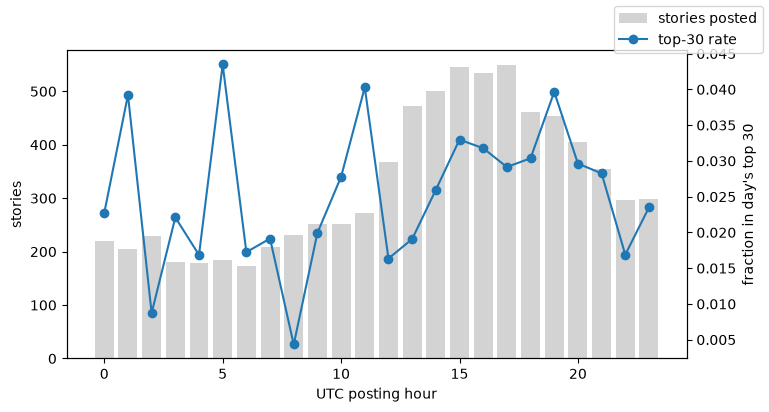

In [5]:
fig, ax1 = plt.subplots(figsize=(8, 4))
by_hour = df.groupby("hour_utc").agg(n=("top30", "size"), rate=("top30", "mean"))
ax1.bar(by_hour.index, by_hour.n, color="lightgray", label="stories posted")
ax2 = ax1.twinx(); ax2.plot(by_hour.index, by_hour.rate, "o-", label="top-30 rate")
ax1.set(xlabel="UTC posting hour", ylabel="stories"); ax2.set(ylabel="fraction in day's top 30")
fig.legend(loc="upper right"); fig.savefig(FIG / "hour_of_day.png", dpi=120, bbox_inches="tight")

## Takeaway

- **Misses are quiet, not mis-read.** The 36 missed positives averaged 2.5 points at 30 minutes
  against 31.6 for the caught ones; most had no comment yet. The model ranked them with the other
  2,400 two-point stories because at 30 minutes they *were* two-point stories. Nothing in the title
  or domain separates "The Singularity will occur on a Tuesday" (2 points, finished at 1,262) from
  the stories around it. Missed positives were also posted earlier in the UTC day (11:00 vs 16:00),
  consistent with stories that sat unnoticed until US daytime traffic or HN's second-chance pool
  picked them up.
- **False alarms are mostly mainstream news and politics**: BBC, NYT, Wired, The Hill, with 8-30
  points at 30 minutes that plateaued at 30-100. None were marked dead. HN's ranking penalises
  political and flagged stories, which the API does not expose; that is a feature the collector
  cannot see.
- **Posting hour barely matters for this label.** The top-30 rate per hour wanders between 1% and
  4% with no clear day/night pattern, because the label is relative to the posting day: a night
  post competes against fewer stories, but it also gets fewer votes. The hour feature earned a
  small permutation importance in notebook 02 for the same reason.